# Assignment Module 2: Pet Classification

The goal of this assignment is to implement a neural network that classifies images of 37 breeds of cats and dogs from the [Oxford-IIIT-Pet dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/). The assignment is divided into two parts: first, you will be asked to implement from scratch your own neural network for image classification; then, you will fine-tune a pretrained network provided by PyTorch.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


IMPORT

In [19]:
from torch.nn.functional import cross_entropy
from torch.optim import AdamW
from torchsummary import summary
from tqdm import tqdm
from torch.optim.lr_scheduler import OneCycleLR
from torchvision import transforms
from torch import nn, Tensor
from torch.nn import Module, Conv2d, BatchNorm2d, AdaptiveAvgPool2d, Linear, LeakyReLU, MaxPool2d, AvgPool2d, ReLU

import random
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from PIL import Image
from torch import Tensor
from torch.utils.data import Dataset
from typing import List, Tuple

from torch.utils.data import DataLoader

import os
import json

## Dataset

The following cells contain the code to download and access the dataset you will be using in this assignment. Note that, although this dataset features each and every image from [Oxford-IIIT-Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/), it uses a different train-val-test split than the original authors.

In [20]:
def fix_random(seed: int) -> None:
    """Fix all the possible sources of randomness.

    Args:
        seed: the seed to use.
    """
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

fix_random(seed=115)

In [ ]:
# !git clone https://github.com/CVLAB-Unibo/ipcv-assignment-2.git

In [4]:
os.chdir("/content/drive/MyDrive/assignment_2/dataset")
os.getcwd()

'/content/drive/MyDrive/assignment_2/dataset'

In [21]:
class OxfordPetDataset(Dataset):
    def __init__(self, split: str, transform=None) -> None:
        super().__init__()

        self.root = Path("ipcv-assignment-2") / "dataset"
        self.split = split
        self.names, self.labels = self._get_names_and_labels()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx) -> Tuple[Tensor, int]:
        img_path = self.root / "images" / f"{self.names[idx]}.jpg"
        img = Image.open(img_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            img = self.transform(img)

        return img, label

    def get_num_classes(self) -> int:
        return max(self.labels) + 1

    def _get_names_and_labels(self) -> Tuple[List[str], List[int]]:
        names = []
        labels = []

        with open(self.root / "annotations" / f"{self.split}.txt") as f:
            for line in f:
                name, label = line.replace("\n", "").split(" ")
                names.append(name),
                labels.append(int(label) - 1)

        return names, labels

## Part 1: design your own network

Your goal is to implement a convolutional neural network for image classification and train it from scratch on `OxfordPetDataset`. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~60%. You are free to achieve this however you want, except for a few rules you must follow:

- Compile this notebook by displaying the results obtained by the best model you found throughout your experimentation; then show how, by removing some of its components, its performance drops. In other words, do an *ablation study* to prove that your design choices have a positive impact on the final result.

- Do not instantiate an off-the-self PyTorch network. Instead, construct your network as a composition of existing PyTorch layers. In more concrete terms, you can use e.g. `torch.nn.Linear`, but you cannot use e.g. `torchvision.models.alexnet`.

- Show your results and ablations with plots, tables, images, etc. — the clearer, the better.

Don't be too concerned with your model performance: the ~60% is just to give you an idea of when to stop. Keep in mind that a thoroughly justified model with lower accuracy will be rewarded more points than a poorly experimentally validated model with higher accuracy.

In [22]:
def get_device():
    if torch.backends.mps.is_available():
        device = "mps"
    elif torch.cuda.is_available():
        device = "cuda"
    else:
        device = "cpu"
    return device

In [23]:
def save_model(model, path: str, epoch: int, best: bool = False, epoch_freq: int = 0) -> None:
    os.makedirs(path, exist_ok=True)
    if best:
        # print(f"Saving best model at epoch {epoch} to {path}")
        torch.save(model.state_dict(), os.path.join(path, "best_model.pt"))
    else:
        # print(f"Saving last model to {path}")
        torch.save(model.state_dict(), os.path.join(path, "last_model.pt"))

    if epoch_freq > 0 and epoch % epoch_freq == 0:
        # print(f"Saving model at epoch {epoch} to {path}")
        torch.save(model.state_dict(), os.path.join(path, f"epoch_{epoch}.pt"))


# Hyperparameters

In [ ]:
NUM_CLASSES = 37
cfg = {
    #Saving parameters
    "save_freq": 0,

    # Pre-processing's parameters.
    "train_size": 112,
    "mean": [0.485, 0.456, 0.406],
    "std": [0.229, 0.224, 0.225],
    "test_size": 128,
    "crop_size": 112,
    "augmentation": True,

    # Training's parameters.
    "batch_size": 32,
    "num_epochs": 130,
    "base_channels": 16,

    # Optimizer's parameters.
    "max_lr": 1.5e-3,
    "schedule_lr": True
}

In [28]:
transform = transforms.Compose([transforms.Resize((cfg["train_size"], cfg["train_size"])),
                                transforms.ToTensor()])
dataset = OxfordPetDataset(split="train", transform=transform)

def compute_mean_std(dataset, batch_size=32):
    """Compute mean and std of a dataset."""
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    mean = 0.
    std = 0.
    total_images_count = 0

    for images, _ in tqdm(loader, desc="Computing mean and std"):

        batch_samples = images.size(0)  # [B, C, H, W]
        images = images.view(batch_samples, images.size(1), -1)  # [B, C, H*W]


        mean += images.mean(2).sum(0)
        std += images.std(2).sum(0)
        total_images_count += batch_samples

    mean /= total_images_count
    std /= total_images_count

    return mean, std

mean, std = compute_mean_std(dataset)

print(f"Mean: {mean}")
print(f"Std: {std}")

Computing mean and std: 100%|██████████| 115/115 [00:09<00:00, 12.11it/s]

Mean: tensor([0.4845, 0.4529, 0.3959])
Std: tensor([0.2216, 0.2191, 0.2211])


In [13]:
class TripleConvBlock(Module):
    def __init__(self, in_ch: int, out_ch: int, downsample: bool = True, skip: bool = True, batch_norm: bool = True, activation = LeakyReLU) -> None:
        super().__init__()

        self.skip = skip
        self.batch_norm = batch_norm

        self.conv1 = Conv2d(in_ch, out_ch, 3, 1, 1, bias=False)
        self.conv2 = Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.conv3 = Conv2d(out_ch, out_ch, 3, 1, 1, bias=False) #if not downsample else Conv2d(in_ch, out_ch, 3, 2, 1, bias=False)

        if batch_norm:
            self.bn1 = BatchNorm2d(out_ch)
            self.bn2 = BatchNorm2d(out_ch)
            self.bn3 = BatchNorm2d(out_ch)

        self.act  = activation()
        self.pool = MaxPool2d(2) if downsample else nn.Identity()

        if skip:
            self.skip_adapt = nn.Sequential(
                MaxPool2d(2) if downsample else nn.Identity(),
                Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
                BatchNorm2d(out_ch)
            )


        self.need_changes = downsample or (in_ch != out_ch)


    def forward(self, x: Tensor) -> Tensor:
        if self.skip:
            identity = x if not self.need_changes else self.skip_adapt(x)

        if self.batch_norm:
            out = self.act(self.bn1(self.conv1(x)))
            out = self.act(self.bn2(self.conv2(out)))
            out = self.bn3(self.conv3(out))
        else:
            out = self.act(self.conv1(x))
            out = self.act(self.conv2(out))
            out = self.conv3(out)

        out = self.pool(out)

        if self.skip:
            out = self.act(out + identity)

        return out


class FullModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__()
        self.conv_block1 = TripleConvBlock(3, base_channels)
        self.conv_block2 = TripleConvBlock(base_channels, base_channels * 2)
        self.conv_block3 = TripleConvBlock(base_channels * 2, base_channels * 4)
        self.conv_block4 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False)
        self.conv_block5 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False)
        self.gap = AdaptiveAvgPool2d(1)
        self.fc = Linear(base_channels * 4, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.conv_block5(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x



In [17]:
full_model = FullModel(num_classes=NUM_CLASSES, base_channels=cfg["base_channels"])
summary(full_model, input_size=(3, cfg["train_size"], cfg["train_size"]))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
         MaxPool2d-1            [-1, 3, 56, 56]               0
            Conv2d-2           [-1, 16, 56, 56]              48
       BatchNorm2d-3           [-1, 16, 56, 56]              32
            Conv2d-4         [-1, 16, 112, 112]             432
       BatchNorm2d-5         [-1, 16, 112, 112]              32
         LeakyReLU-6         [-1, 16, 112, 112]               0
            Conv2d-7         [-1, 16, 112, 112]           2,304
       BatchNorm2d-8         [-1, 16, 112, 112]              32
         LeakyReLU-9         [-1, 16, 112, 112]               0
           Conv2d-10         [-1, 16, 112, 112]           2,304
      BatchNorm2d-11         [-1, 16, 112, 112]              32
        MaxPool2d-12           [-1, 16, 56, 56]               0
        LeakyReLU-13           [-1, 16, 56, 56]               0
  TripleConvBlock-14           [-1, 16,

## Ablation Models

In [10]:
class OneBlockLessModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__()
        self.conv_block1 = TripleConvBlock(3, base_channels)
        self.conv_block2 = TripleConvBlock(base_channels, base_channels * 2)
        self.conv_block3 = TripleConvBlock(base_channels * 2, base_channels * 4)
        self.conv_block4 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False)
        self.gap = AdaptiveAvgPool2d(1)
        self.fc = Linear(base_channels * 4, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

In [11]:
class DoubleConvBlock(Module):
    def __init__(self, in_ch: int, out_ch: int, downsample: bool = True) -> None:
        super().__init__()

        self.conv1 = Conv2d(in_ch, out_ch, 3, 1, 1, bias=False)
        self.conv2 = Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)

        self.bn1 = BatchNorm2d(out_ch)
        self.bn2 = BatchNorm2d(out_ch)


        self.act  = LeakyReLU(negative_slope=0.1, inplace=True)
        self.pool = MaxPool2d(2) if downsample else nn.Identity()

        self.skip_adapt = nn.Sequential(
                MaxPool2d(2) if downsample else nn.Identity(),
                Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
                BatchNorm2d(out_ch)
            )

        self.need_changes = downsample or (in_ch != out_ch)


    def forward(self, x: Tensor) -> Tensor:
        identity = x if not self.need_changes else self.skip_adapt(x)

        out = self.act(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.pool(out)

        out = self.act(out + identity)
        return out

class DoubleConvBlockModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__()
        self.conv_block1 = DoubleConvBlock(3, base_channels)
        self.conv_block2 = DoubleConvBlock(base_channels, base_channels * 2)
        self.conv_block3 = DoubleConvBlock(base_channels * 2, base_channels * 4)
        self.conv_block4 = DoubleConvBlock(base_channels * 4, base_channels * 4, downsample=False)
        self.conv_block5 = DoubleConvBlock(base_channels * 4, base_channels * 4, downsample=False)
        self.gap = AdaptiveAvgPool2d(1)
        self.fc = Linear(base_channels * 4, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.conv_block5(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [12]:
class NoSkipModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__()
        self.conv_block1 = TripleConvBlock(3, base_channels, skip=False)
        self.conv_block2 = TripleConvBlock(base_channels, base_channels * 2, skip=False)
        self.conv_block3 = TripleConvBlock(base_channels * 2, base_channels * 4, skip=False)
        self.conv_block4 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False, skip=False)
        self.conv_block5 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False, skip=False)
        self.gap = AdaptiveAvgPool2d(1)
        self.fc = Linear(base_channels * 4, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.conv_block5(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

In [13]:
class NoBatchNormModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__()
        self.conv_block1 = TripleConvBlock(3, base_channels, batch_norm=False)
        self.conv_block2 = TripleConvBlock(base_channels, base_channels * 2, batch_norm=False)
        self.conv_block3 = TripleConvBlock(base_channels * 2, base_channels * 4, batch_norm=False)
        self.conv_block4 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False, batch_norm=False)
        self.conv_block5 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False, batch_norm=False)
        self.gap = AdaptiveAvgPool2d(1)
        self.fc = Linear(base_channels * 4, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.conv_block5(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [14]:
class ReluModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__()
        self.conv_block1 = TripleConvBlock(3, base_channels, activation=ReLU)
        self.conv_block2 = TripleConvBlock(base_channels, base_channels * 2, activation=ReLU)
        self.conv_block3 = TripleConvBlock(base_channels * 2, base_channels * 4, activation=ReLU)
        self.conv_block4 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False, activation=ReLU)
        self.conv_block5 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False, activation=ReLU)
        self.gap = AdaptiveAvgPool2d(1)
        self.fc = Linear(base_channels * 4, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.conv_block5(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

In [15]:
class NoGlobalAvgPoolModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__()
        self.conv_block1 = TripleConvBlock(3, base_channels)
        self.conv_block2 = TripleConvBlock(base_channels, base_channels * 2)
        self.conv_block3 = TripleConvBlock(base_channels * 2, base_channels * 4)
        self.conv_block4 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False)
        self.conv_block5 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False)
        self.fc = Linear(base_channels * 4 * 14 * 14 , num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.conv_block5(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

In [16]:
def get_data_loaders(cfg):
    train_size = cfg["train_size"]
    test_size = cfg["test_size"]
    crop_size = cfg["crop_size"]
    mean = cfg["mean"]
    std = cfg["std"]
    augmentations = cfg["augmentation"]
    batch_size = cfg["batch_size"]

    if augmentations:
        train_tfms = transforms.Compose([
                    transforms.RandomResizedCrop(crop_size),
                    transforms.RandomHorizontalFlip(p=0.5),
                    transforms.ToTensor(),
                    transforms.Normalize(mean=mean, std=std),
                ])

        test_tfms = transforms.Compose([
            transforms.Resize(test_size),
            transforms.CenterCrop(crop_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ])

    else:
        train_tfms = transforms.Compose([
            transforms.Resize((train_size, train_size)),
            transforms.ToTensor()
        ])

        test_tfms = transforms.Compose([
            transforms.Resize((test_size, test_size)),
            transforms.ToTensor()
        ])


    train = OxfordPetDataset(split="train", transform=train_tfms)
    validation = OxfordPetDataset(split="val", transform=test_tfms)
    test = OxfordPetDataset(split="test", transform=test_tfms)

    nw = max(2, os.cpu_count() * 3 // 4)

    train_loader = DataLoader(train, batch_size=batch_size, shuffle=True, num_workers=nw)
    validation_loader = DataLoader(validation, batch_size=batch_size, shuffle=False, num_workers=nw)
    test_loader = DataLoader(test, batch_size=batch_size, shuffle=False, num_workers=nw)

    return train_loader, validation_loader, test_loader

### RUN ALL EXPERIMENTS

SAVE RESULTS

In [17]:
def save_results_json(model_name: str, dictionary: dict, path: str = "./results.json") -> None:
    """Save results to a JSON file without deleting existing entries."""

    # 1. Leggi il file esistente se c'è
    if os.path.exists(path):
        with open(path, "r") as f:
            try:
                data = json.load(f)
            except json.JSONDecodeError:
                data = {}  # se il file è vuoto o corrotto
    else:
        data = {}

    # 2. Aggiorna o aggiungi il modello
    data[model_name] = dictionary

    # 3. Riscrivi il file con tutto il contenuto
    with open(path, "w") as f:
        json.dump(data, f, indent=4)


In [28]:
def run_experiment(model_name, current_model, config, parameter_to_change):

    # get a copy of config to avoid modifying the original
    cfg = config.copy()
    if parameter_to_change:
        param_name, param_value = parameter_to_change
        cfg[param_name] = param_value

    train_loader, validation_loader, test_loader = get_data_loaders(cfg)

    epochs = cfg["num_epochs"]
    base_channels = cfg["base_channels"]
    model_name = model_name
    max_lr = cfg["max_lr"]
    save_freq = cfg["save_freq"]
    schedule_lr = cfg["schedule_lr"]

    device = get_device()
    #print(f"Using device: {device}")


    model = current_model(NUM_CLASSES, base_channels).to(device)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Numero totale di parametri: {total_params}")

    criterion = cross_entropy
    optimizer = AdamW(model.parameters())
    if schedule_lr:
        lr_scheduler = OneCycleLR(optimizer, max_lr=max_lr, steps_per_epoch=len(train_loader), epochs=epochs)

    lr_values = []
    losses = []
    val_losses = []
    val_accuracies = []
    train_accuracies = []
    total = 0
    correct = 0
    for epoch in range(epochs):

        model.train()
        epoch_loss = 0.0

        for imgs, labels in tqdm(train_loader):

            imgs = imgs.to(device)
            labels = labels.to(device)

            preds = model(imgs)

            # compute gradients
            loss = criterion(preds, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            if schedule_lr:
                lr_scheduler.step()


            epoch_loss += loss.item()

            _, predicted = torch.max(preds, dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)


        train_accuracy = correct / total
        train_accuracies.append(train_accuracy)
        # print(f"Train Accuracy: {train_accuracy:.6f}")

        epoch_loss /= len(train_loader)
        losses.append(epoch_loss)
        # print(f"Epoch {epoch + 1}/{epochs}, Loss: {epoch_loss:.6f}")

        save_model(model, f"./checkpoints/{model_name}", epoch=epoch, best=False, epoch_freq=save_freq)

        # Validation
        model.eval()
        val_loss = 0.0
        total = 0
        correct = 0
        with torch.no_grad():
            for imgs, labels in validation_loader:
                imgs = imgs.to(device)
                labels = labels.to(device)

                preds = model(imgs)
                loss = criterion(preds, labels)
                val_loss += loss.item()


                _, predicted = torch.max(preds, dim=1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        val_loss /= len(validation_loader)
        val_losses.append(val_loss)
        # print(f"Validation Loss: {val_loss:.6f}")


        val_accuracy = correct / total
        val_accuracies.append(val_accuracy)
        # print(f"Validation Accuracy: {val_accuracy:.6f}")

        current_lr = optimizer.param_groups[0]["lr"]

        lr_values.append(current_lr)

        print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Acc: {train_accuracy:.6f} | "
        f"Train Loss: {epoch_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Val Acc: {val_accuracy:.6f} |"
        f"LR: {current_lr:.6f}"
        )

        if val_loss <= min(val_losses, default=float('inf')):
            save_model(model, f"./checkpoints/{model_name}", epoch=epoch, best=True, epoch_freq=0)


    model_best = current_model(NUM_CLASSES, base_channels).to(device)
    model_best.load_state_dict(torch.load(f"./checkpoints/{model_name}/best_model.pt"))

    model_best.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, labels in test_loader: # tqdm(test_loader):
            imgs = imgs.to(device)
            labels = labels.to(device)

            preds = model_best(imgs)
            _, predicted = torch.max(preds, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    accuracy = correct / total
    print(f"Test Accuracy: {accuracy:.4f}")

    dictionary = {
        "cfg": cfg,
        "train_losses": losses,
        "train_accuracies": train_accuracies,
        "val_losses": val_losses,
        "val_accuracies": val_accuracies,
        "lr_values": lr_values,
        "params": total_params,
        "test_accuracy": accuracy
    }
    save_results_json(model_name,dictionary, path="./results.json")

In [19]:
all_models = {
    'full_model': {'model': FullModel, 'parameter_to_change': None},
    'one_block_less_model': {'model': OneBlockLessModel, 'parameter_to_change': None},
    'double_conv_model': {'model': DoubleConvBlockModel, 'parameter_to_change': None},
    'no_skip_model': {'model': NoSkipModel, 'parameter_to_change': None},
    'no_batch_norm_model': {'model': NoBatchNormModel, 'parameter_to_change': None},
    'relu_model': {'model': ReluModel, 'parameter_to_change': None},
    'no_global_avg_pool_model': {'model': NoGlobalAvgPoolModel, 'parameter_to_change': None},
    'less_channels_model': {'model': FullModel, 'parameter_to_change': ('base_channels', 8)},
    'no_augmentation_model': {'model': FullModel, 'parameter_to_change': ('augmentation', False)},
    'fixed_lr_model': {'model': FullModel, 'parameter_to_change': ('schedule_lr', False)},
}

In [29]:
for model_name, model_info in all_models.items():
    print(f"Running experiment for model: {model_name}")
    run_experiment(
        model_name=model_name,
        current_model=model_info['model'],
        config=cfg,
        parameter_to_change=model_info['parameter_to_change']
    )

Running experiment for model: full_model
Numero totale di parametri: 356549


100%|██████████| 115/115 [00:05<00:00, 20.16it/s]


Epoch [1/130] | Train Acc: 0.044971 | Train Loss: 3.648418 | Val Loss: 3.527962 | Val Acc: 0.065431 |LR: 0.000062


100%|██████████| 115/115 [00:05<00:00, 19.93it/s]


Epoch [2/130] | Train Acc: 0.071234 | Train Loss: 3.450962 | Val Loss: 3.414908 | Val Acc: 0.091603 |LR: 0.000069


100%|██████████| 115/115 [00:05<00:00, 19.97it/s]


... (2,591 outputs left out)

100%|██████████| 115/115 [00:05<00:00, 19.41it/s]


Epoch [129/130] | Train Acc: 0.694712 | Train Loss: 0.812591 | Val Loss: 1.273400 | Val Acc: 0.650491 |LR: 0.001000


100%|██████████| 115/115 [00:05<00:00, 19.18it/s]


Epoch [130/130] | Train Acc: 0.715065 | Train Loss: 0.841102 | Val Loss: 1.403176 | Val Acc: 0.624318 |LR: 0.001000
Test Accuracy: 0.6696


In [2]:
def read_history(path: str = "./results.json") -> List[float]:
    """Read validation losses from the results JSON file."""
    with open(path, "r") as f:
        data = json.load(f)

    return data

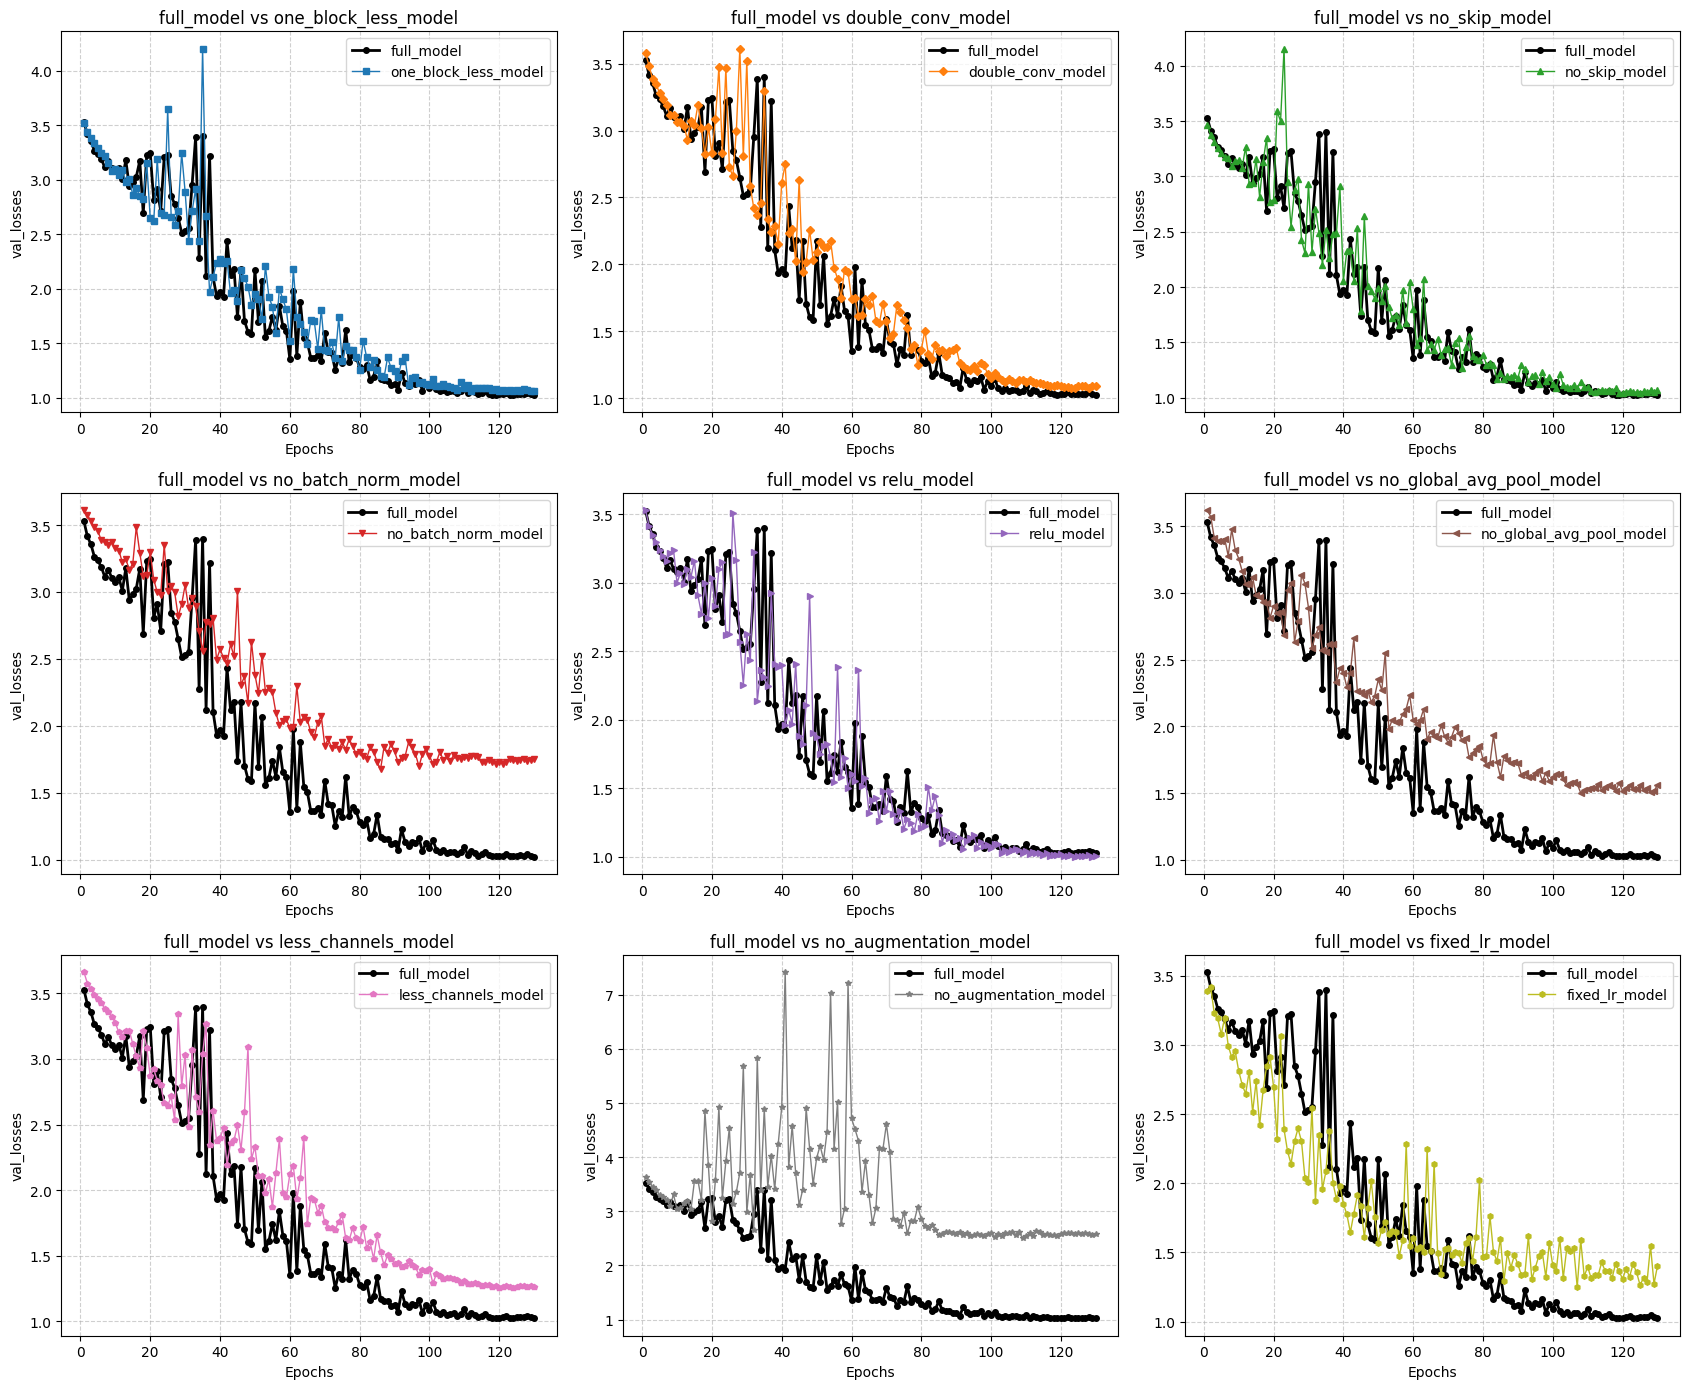

In [3]:
history = read_history()

def plot_history(history: dict, plot_type: str) -> None:

    baseline_color = "black"
    baseline_marker = "o"
    colors = plt.cm.tab10.colors
    markers = ['s', 'D', '^', 'v', '>', '<', 'p', '*', 'h']

    # 3x3 grid of subplots
    fig, axes = plt.subplots(3, 3, figsize=(17, 14))
    axes = axes.flatten()

    baseline_losses = history["full_model"][plot_type]
    epochs = range(1, len(baseline_losses) + 1)

    other_models = [m for m in history if m != "full_model"]

    for idx, model_name in enumerate(other_models):
        ax = axes[idx]
        
        # Plot baseline
        ax.plot(
            epochs, baseline_losses,
            label="full_model",
            color=baseline_color,
            marker=baseline_marker,
            linewidth=2,
            markersize=4
        )
        
        # Plot other model
        ax.plot(
            epochs, history[model_name][plot_type],
            label=model_name,
            color=colors[idx % len(colors)],
            marker=markers[idx % len(markers)],
            linewidth=1,
            markersize=4
        )
        
        ax.set_title(f"full_model vs {model_name}")
        ax.set_xlabel("Epochs")
        ax.set_ylabel(plot_type)
        ax.grid(True, linestyle="--", alpha=0.6)
        ax.legend()

    plt.tight_layout()
    plt.show()

plot_history(history, "val_losses")

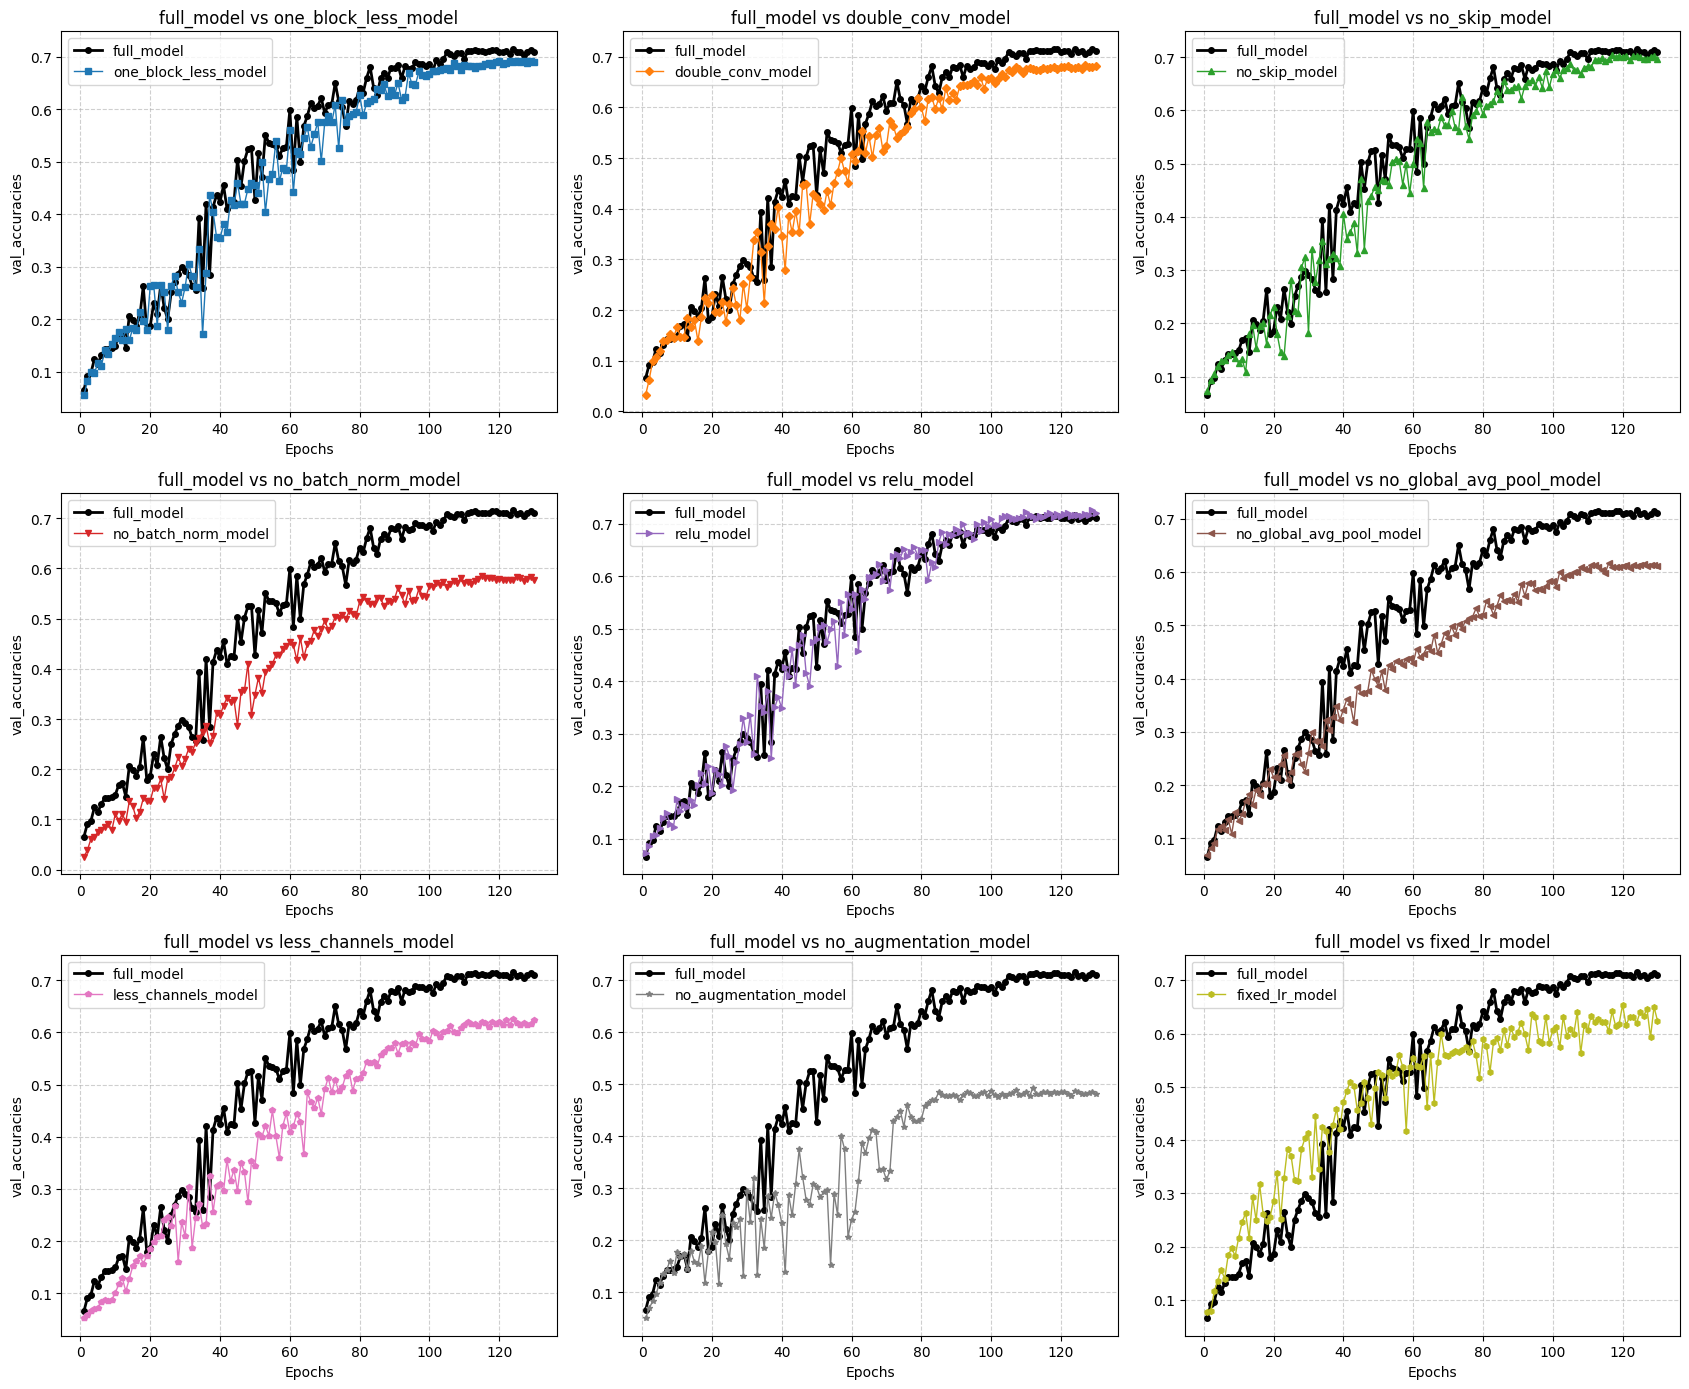

In [4]:
plot_history(history, "val_accuracies")

In [ ]:
df = pd.DataFrame(columns=["model", "num_params", "train_accuracy", "val_accuracy", "test_accuracy"])
for model_name, data in history.items():

    df.loc[len(df)] = [
        model_name,
        data["params"],
        data["train_accuracies"][-1],
        data["val_accuracies"][-1],
        data["test_accuracy"]
    ]

df

,model,num_params,train_accuracy,val_accuracy,test_accuracy
0,full_model,356549,0.798655,0.710469,0.727519
1,one_block_less_model,241349,0.769580,0.690840,0.705850
2,double_conv_model,233957,0.752135,0.682661,0.692849
3,no_skip_model,345269,0.748683,0.695747,0.719393
4,no_batch_norm_model,355109,0.704707,0.577972,0.574215
5,relu_model,356549,0.794839,0.720284,0.716143
6,no_global_avg_pool_model,818309,0.734327,0.610687,0.626219
7,less_channels_model,90357,0.650736,0.623773,0.647887
8,no_augmentation_model,356549,0.828639,0.480371,0.527627
9,fixed_lr_model,356549,0.715065,0.624318,0.669556


## Part 2: fine-tune an existing network

Your goal is to fine-tune a pretrained ResNet-18 model on `OxfordPetDataset`. Use the implementation provided by PyTorch, i.e. the opposite of part 1. Specifically, use the PyTorch ResNet-18 model pretrained on ImageNet-1K (V1). Divide your fine-tuning into two parts:

2A. First, fine-tune the ResNet-18 with the same training hyperparameters you used for your best model in part 1.

2B. Then, tweak the training hyperparameters in order to increase the accuracy on the test split. Justify your choices by analyzing the training plots and/or citing sources that guided you in your decisions — papers, blog posts, YouTube videos, or whatever else you may find useful. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~90%.